# Train station riders: what is the weather worth, at best?

**Before building a feed of weather forecasts into a ridership model, hand the model the weather that really came. No forecast can beat that, so what it gains is a ceiling. At 20 Chicago train stations the ceiling is under 2% of the miss on weekdays and 8% on weekends: 24% at one station, and nothing at two of the three stations with the quietest weekends. A forecast anyone can make, "tomorrow like today", keeps half of the weekend gain. The test took the same cases and the same forecaster, with one table added.**

A new input costs a pipeline: a supplier, a feed, a place to keep its history, and a way to cope when it is late. The cheap question comes first. If the model knew this input perfectly, how much better would the forecast be? If the answer is "hardly", nothing has to be built. If it is "a lot, on these days, at these stations", the feed has a target to meet.

*Data: riders entering 20 stations of Chicago's "L" trains each day, with the day's weather, January 2011 to August 2016, from the R package modeldata ([source and license](data/README.md#chicago-ridership)). To run this notebook yourself, see [Run an example yourself](../docs/examples.md#run-an-example-yourself).*

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from pandas.tseries.holiday import USFederalHolidayCalendar

from timegym import Pipeline, cases_from_series
from timegym.statistics import paired_t_interval

from example_data import load  # examples/example_data.py, next to this notebook

plt.rcParams.update({"figure.figsize": (12, 4), "figure.dpi": 110, "font.size": 11,
                     "figure.facecolor": "white", "axes.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "legend.frameon": False, "axes.titlelocation": "left"})

## Twenty stations and the weather

The table has one row a day: the riders who entered each of 20 stations, and five columns on that day's weather. Three are used here. `temp` is the day's average temperature in degrees Fahrenheit. `rain` and `snow` run from 0 to 1 and give the share of the day's weather reports that had rain or snow, so 1 is a day when it never stopped.

Every station has the same week: five busy days and a quiet weekend. How quiet differs a lot. At Washington/Wells a weekend day has a seventh of a weekday's riders, at Belmont half.

Some days follow a calendar of their own: public holidays, the day after Thanksgiving, and the days from Christmas Eve to New Year. They are left out of the scoring here and out of what the model learns about weather. A model for those days needs a calendar, which is what [Tomorrow's electricity demand](electricity-demand.ipynb) builds.

20 stations, 2,053 days, 01 January 2011 to 14 August 2016
Days left out as holidays: 96
A weekend day as a share of a weekday: Washington/Wells 14% to Belmont 52%


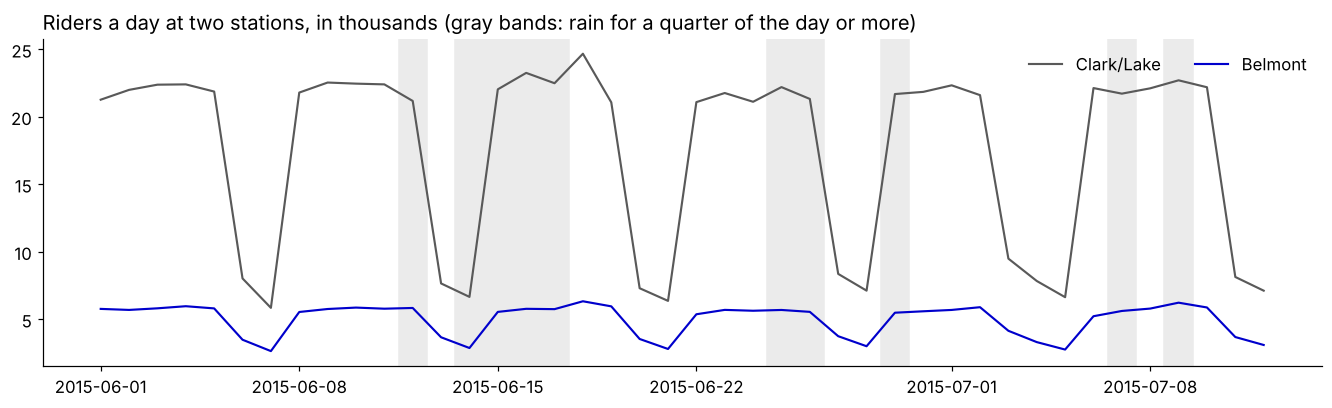

In [2]:
table = load("chicago-ridership")
weather = table[["temp", "rain", "snow"]]
riders = table.drop(columns=["temp", "rain", "snow", "storm", "wind"])
days = riders.index

public = USFederalHolidayCalendar().holidays(days[0], days[-1])
after_thanksgiving = (days.month == 11) & (days.day_of_week == 4) & (days.day >= 23) & (days.day <= 29)
year_end = ((days.month == 12) & (days.day >= 24)) | ((days.month == 1) & (days.day == 1))
ordinary = pd.Series(~(days.isin(public) | after_thanksgiving | year_end), index=days)
weekend = pd.Series(days.day_of_week >= 5, index=days)

SLASHED = {"Clark_Lake": "Clark/Lake", "Quincy_Wells": "Quincy/Wells",
           "Washington_Wells": "Washington/Wells", "Archer_35th": "35th/Archer"}


def label(name):
    return SLASHED.get(name, name.replace("_", " "))


quiet = (riders[weekend & ordinary].median() / riders[~weekend & ordinary].median()).sort_values()
print(f"{riders.shape[1]} stations, {len(days):,} days, {days[0]:%d %B %Y} to {days[-1]:%d %B %Y}")
print(f"Days left out as holidays: {(~ordinary).sum()}")
print(f"A weekend day as a share of a weekday: {label(quiet.index[0])} {quiet.iloc[0]:.0%}"
      f" to {label(quiet.index[-1])} {quiet.iloc[-1]:.0%}")

window = slice("2015-06-01", "2015-07-12")
fig, ax = plt.subplots(figsize=(12, 3.6), layout="constrained")
for name, color in [("Clark_Lake", "0.35"), ("Belmont", "#0000CC")]:
    ax.plot(riders.loc[window, name] / 1000, color=color, linewidth=1.4, label=label(name))
for day in weather.loc[window].index[weather.loc[window, "rain"] > 0.25]:
    ax.axvspan(day - pd.Timedelta(hours=12), day + pd.Timedelta(hours=12), color="0.92")
ax.set_title("Riders a day at two stations, in thousands (gray bands: rain for a quarter of the day or more)")
ax.legend(loc="upper right", ncols=2)
plt.show()

assert riders.shape == (2053, 20) and not table.isna().any().any()
assert list(quiet.index[:3]) == ["Washington_Wells", "Quincy_Wells", "Merchandise_Mart"]
assert quiet.index[-1] == "Belmont" and (~ordinary).sum() == 96
assert 0.12 < quiet.iloc[0] < 0.16 and 0.45 < quiet.iloc[-1] < 0.6

## The forecast to beat

The forecast for a day is its **usual level**: the middle value of the same weekday over the last eight weeks, station by station. It is made the evening before, for every day from January 2013 on.

The miss is in riders, as a share of what the station usually carries on that kind of day, and averaged over the 20 stations. A weekend is harder to forecast than a weekday in those terms.

In [3]:
SAME_DAYS = 8                          # the usual level looks at this many same weekdays


def usual(values, rows):
    # The middle value of the same weekday over the weeks before each row.
    back = rows[:, None] - 7 * np.arange(1, SAME_DAYS + 1)
    return np.median(values[back], axis=1)


class Usual:
    def fit(self, history):
        self.values_ = np.asarray(history, dtype=float)
        return self

    def predict(self, dates):
        return usual(self.values_, np.array([len(self.values_)]))


first = days.get_loc(pd.Timestamp("2013-01-01"))
test_days = days[first:]
cases = cases_from_series(riders, list(range(first, len(days))), horizon=1, name="riders")
kinds = {"Weekdays": (ordinary & ~weekend)[test_days].to_numpy(),
         "Weekends": (ordinary & weekend)[test_days].to_numpy()}
level = {kind: riders.loc[test_days[mask]].median().to_numpy() for kind, mask in kinds.items()}


def misses(model):
    # The miss in riders for every test day and station.
    run = Pipeline(model).run(cases=cases, keep_data=True)
    assert run.report.summary["status_counts"]["ERROR"] == 0
    return np.array([np.abs(entry.forecast.point[0] - np.asarray(entry.observed)[0])
                     for entry in run.cases])


def share(miss, kind):
    # The average miss as a percentage of the usual riders, one number per station.
    return miss[kinds[kind]].mean(axis=0) / level[kind] * 100


miss = {"Usual level": misses(Usual())}
for kind, mask in kinds.items():
    print(f"{kind}: {mask.sum()} days, the usual level misses by "
          f"{share(miss['Usual level'], kind).mean():.1f}% of the usual riders")

assert kinds["Weekdays"].sum() == 891 and kinds["Weekends"].sum() == 372
assert round(share(miss["Usual level"], "Weekdays").mean(), 1) == 5.2
assert round(share(miss["Usual level"], "Weekends").mean(), 1) == 11.4

Weekdays: 891 days, the usual level misses by 5.2% of the usual riders
Weekends: 372 days, the usual level misses by 11.4% of the usual riders


## Hand it the answer

The second forecaster starts from the usual level and corrects it for the weather. In `fit` it looks at up to two years of its history and learns, for each station, how far riders were above or below the usual level when the day was warmer, rainier or snowier than the eight days the usual level came from. Weekdays and weekends get weights of their own.

In `predict` it needs the weather of the day it is forecasting, which nobody has the evening before. Here it reads it from the table of what the weather turned out to be. That is cheating, and it is the point: a real weather forecast can only do worse than the truth, so this run is the most the weather can be worth to this forecaster.

Nothing else moves. The cases, the history each forecast may see, and the scoring are the same as before.

In [4]:
LEARN_DAYS = 730                       # the weather weights are learned on the last two years


class WithWeather(Usual):
    def __init__(self, weather, ordinary, told=None):
        self.weather = weather                              # what the weather was, one row a day
        self.ordinary = ordinary                            # False on the days left out as holidays
        self.told = weather if told is None else told       # what the model hears about the day ahead

    def _rows(self, dates):
        return np.asarray((pd.DatetimeIndex(dates) - self.weather.index[0]).days)

    def _behind(self, rows):
        # The average weather on the days the usual level is made of.
        back = rows[:, None] - 7 * np.arange(1, SAME_DAYS + 1)
        return self.weather.to_numpy()[back].mean(axis=1)

    def fit(self, history):
        super().fit(history)
        at = np.arange(max(7 * SAME_DAYS, len(history) - LEARN_DAYS), len(history))
        learn_days = history.index[at]
        with np.errstate(divide="ignore", invalid="ignore"):
            above = np.log(self.values_[at] / usual(self.values_, at))       # riders against the usual level
        rows = self._rows(learn_days)
        change = self.weather.to_numpy()[rows] - self._behind(rows)
        keep = self.ordinary[learn_days].to_numpy() & np.isfinite(above).all(axis=1)
        above = np.clip(above, -np.log(5), np.log(5))
        self.weights_ = {}
        for is_weekend in (False, True):
            part = keep & ((learn_days.day_of_week >= 5) == is_weekend)
            columns = np.column_stack([np.ones(part.sum()), change[part]])
            self.weights_[is_weekend] = np.linalg.lstsq(columns, above[part], rcond=None)[0][1:]
        return self

    def predict(self, dates):
        rows = self._rows(dates)
        change = self.told.to_numpy()[rows] - self._behind(rows)
        weights = self.weights_[bool(pd.DatetimeIndex(dates)[0].day_of_week >= 5)]
        return super().predict(dates) * np.exp(change @ weights)


def gain(name, kind):
    # How much smaller the miss is than the usual level's, in percent, with an interval over days.
    less = (miss["Usual level"] - miss[name])[kinds[kind]] / level[kind]      # day by station
    found = paired_t_interval(less.mean(axis=1))
    whole = share(miss["Usual level"], kind).mean() / 100
    return found["mean"] / whole * 100, [end / whole * 100 for end in found["ci95"]]


miss["Told the weather"] = misses(WithWeather(weather, ordinary))
rows = {}
for kind in kinds:
    percent, (low, high) = gain("Told the weather", kind)
    rows[kind] = {"Usual level": share(miss["Usual level"], kind).mean(),
                  "Told the weather": share(miss["Told the weather"], kind).mean(),
                  "Less (%)": percent, "from": low, "to": high}
best_case = pd.DataFrame(rows).T
display(best_case.round(1).rename_axis("Miss (%)"))

assert best_case.round(1).loc["Weekdays"].tolist() == [5.2, 5.1, 1.6, 0.2, 3.1]
assert best_case.round(1).loc["Weekends"].tolist() == [11.4, 10.4, 8.3, 5.6, 11.0]

,Usual level,Told the weather,Less (%),from,to
Miss (%),,,,,
Weekdays,5.2,5.1,1.6,0.2,3.1
Weekends,11.4,10.4,8.3,5.6,11.0


The miss is a percentage of the usual riders, and the last three columns say how much smaller it became, with an interval over the days.

On weekdays, knowing the weather takes 1.6% off the miss, and the interval only just clears zero. People go to work whatever the sky does. On weekends it takes 8.3% off, with an interval from 5.6% to 11.0%.

The weekend number is an average over 20 stations, and the stations are far apart.

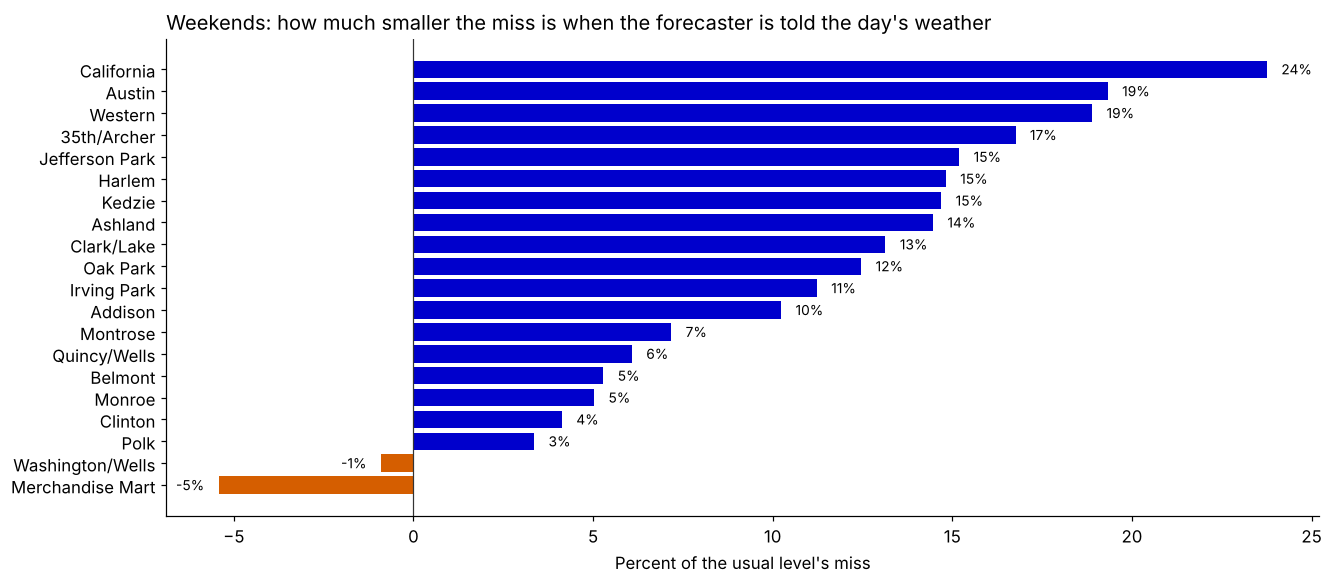

Stations gaining more than 10%: 12 of 20; gaining nothing: 2
Correlation of a station's gain with how busy its weekends are: 0.69


In [5]:
by_station = pd.Series((1 - share(miss["Told the weather"], "Weekends")
                        / share(miss["Usual level"], "Weekends")) * 100, index=riders.columns).sort_values()
labels = [label(name) for name in by_station.index]

fig, ax = plt.subplots(figsize=(12, 5.2), layout="constrained")
ax.barh(labels, by_station, color=np.where(by_station > 0, "#0000CC", "#D55E00"))
ax.axvline(0, color="0.2", linewidth=0.8)
for at, value in enumerate(by_station):
    ax.text(value + (0.4 if value > 0 else -0.4), at, f"{value:.0f}%", va="center",
            ha="left" if value > 0 else "right", fontsize=9)
ax.set_title("Weekends: how much smaller the miss is when the forecaster is told the day's weather")
ax.set_xlabel("Percent of the usual level's miss")
plt.show()

together = float(np.corrcoef(by_station, quiet[by_station.index])[0, 1])
print(f"Stations gaining more than 10%: {(by_station > 10).sum()} of 20; "
      f"gaining nothing: {(by_station <= 0).sum()}")
print(f"Correlation of a station's gain with how busy its weekends are: {together:.2f}")

assert by_station.index[-1] == "California" and round(by_station.iloc[-1]) == 24
assert set(by_station.index[:2]) == {"Washington_Wells", "Merchandise_Mart"} and by_station.iloc[1] < 0
assert (by_station > 10).sum() == 12 and round(together, 2) == 0.69

Twelve stations gain more than 10%, and California gains 24%. Two gain nothing, Washington/Wells and Merchandise Mart, and they are among the three stations with the quietest weekends. The pattern holds across all twenty: the busier a station's weekends are next to its weekdays, the more the weather is worth there (a correlation of 0.69). That fits a simple reading. A weekday trip is to work, and a weekend trip is a choice.

## A forecast anyone can make

The ceiling says what a perfect weather forecast would be worth. The floor is a forecast that costs nothing: tomorrow's weather will be like today's. The same class takes it as a second table, shifted by a day. It still learns its weights from the weather that was, as it would in practice.

In [6]:
miss["Tomorrow like today"] = misses(WithWeather(weather, ordinary, told=weather.shift(1)))

rows = {}
for kind in kinds:
    rows[kind] = {name: share(found, kind).mean() for name, found in miss.items()}
    for name in ["Told the weather", "Tomorrow like today"]:
        percent, (low, high) = gain(name, kind)
        print(f"{kind}, {name.lower()}: {percent:+.1f}% ({low:+.1f} to {high:+.1f})")
display(pd.DataFrame(rows).T.round(2).rename_axis("Miss (%)"))

alike = {column: float(weather[column].corr(weather[column].shift(1))) for column in weather}
print("How alike are a day and the day before? "
      + ", ".join(f"{column} {value:.2f}" for column, value in alike.items()))

floor, (floor_low, floor_high) = gain("Tomorrow like today", "Weekends")
flat, (flat_low, flat_high) = gain("Tomorrow like today", "Weekdays")
assert round(floor, 1) == 4.3 and floor_low > 1 and flat_low < 0 < flat_high
assert alike["temp"] > 0.9 and alike["rain"] < 0.3 and alike["snow"] < 0.5

Weekdays, told the weather: +1.6% (+0.2 to +3.1)
Weekdays, tomorrow like today: -0.6% (-2.0 to +0.9)
Weekends, told the weather: +8.3% (+5.6 to +11.0)
Weekends, tomorrow like today: +4.3% (+1.5 to +7.1)


,Usual level,Told the weather,Tomorrow like today
Miss (%),,,
Weekdays,5.17,5.09,5.20
Weekends,11.37,10.43,10.89


How alike are a day and the day before? temp 0.94, rain 0.27, snow 0.42


"Tomorrow like today" takes 4.3% off the weekend miss, with an interval from 1.5% to 7.1%, which is about half of the ceiling. On weekdays it does nothing that can be told from zero. The last line says why it keeps any of the gain: temperature hardly changes from one day to the next, while rain and snow mostly do. A real forecast is good at tomorrow's rain, so it would land between the floor and the ceiling.

So the feed is worth somewhere between 4% and 8% of the weekend miss, most of it at the stations in the upper half of the picture, and next to nothing on weekdays. Whether that pays for a feed depends on what a weekend miss costs. The question now has a number.

## What the forecaster learned

The weights of a fitted copy say what the weather does to riders, as the forecaster sees it. They are turned into percentages here, and the table gives the middle station.

In [7]:
fitted = WithWeather(weather, ordinary).fit(riders)
effect = {}
for is_weekend, kind in [(False, "Weekdays"), (True, "Weekends")]:
    weights = pd.DataFrame(fitted.weights_[is_weekend], index=weather.columns, columns=riders.columns)
    effect[kind] = {"10 degrees warmer": np.expm1(10 * weights.loc["temp"]).median() * 100,
                    "Rain all day": np.expm1(weights.loc["rain"]).median() * 100,
                    "Snow all day": np.expm1(weights.loc["snow"]).median() * 100}
effect = pd.DataFrame(effect).T
display(effect.round(1).rename_axis("Riders, % change"))

wet = (weather.loc[test_days, "rain"] + weather.loc[test_days, "snow"]).to_numpy() > 0.25
for name, part in [("wet", wet), ("dry", ~wet)]:
    mask = kinds["Weekends"] & part
    before = (miss["Usual level"][mask].mean(axis=0) / level["Weekends"]).mean() * 100
    after = (miss["Told the weather"][mask].mean(axis=0) / level["Weekends"]).mean() * 100
    print(f"Weekend days, {name} ({mask.sum()}): miss {before:.1f}% with the usual level, "
          f"{after:.1f}% told the weather")

assert effect.round(0).loc["Weekends"].tolist() == [4, -16, -14]
assert effect.round(0).loc["Weekdays"].tolist() == [1, -4, -2]
assert wet.sum() > 150 and (kinds["Weekends"] & wet).sum() == 75

,10 degrees warmer,Rain all day,Snow all day
"Riders, % change",,,
Weekdays,0.9,-3.9,-2.1
Weekends,3.8,-16.4,-13.7


Weekend days, wet (75): miss 10.3% with the usual level, 9.1% told the weather
Weekend days, dry (297): miss 11.6% with the usual level, 10.8% told the weather


On a weekend, rain from morning to night takes about 16% off the riders at the middle station, and snow all day about 14%. Ten degrees more adds about 4%. On weekdays the same weather moves riders by 4%, 2% and 1%. The gain is not only on wet days: on the 75 wet weekend days the miss falls from 10.3% to 9.1%, and on the 297 dry ones from 11.6% to 10.8%, where the temperature does the work.

## What TimeGym added

- **The same cases, with one thing changed.** `cases_from_series` cut 1,322 forecasts of the next day once, and three forecasters ran on them. The comparison is day by day and station by station because every forecast is kept.
- **A model that holds what it is told.** A forecaster is any class with `fit` and `predict`, so it can hold a table and look up the dates it is asked for. The pipeline still hands it only the riders of the past. The one thing it knows about the future is the thing we chose to tell it, first the truth and then a guess.
- **Twenty series in one run.** A table with 20 columns gives 20 forecasts a case, and the per-station picture came from the same run as the average.
- **Intervals over days.** `paired_t_interval` said that the weekend gain is real, and that the weekday gain is small enough to argue about.

## Change one thing

- Blur the truth: add an error of a few degrees to `told`, and turn a share of the rainy days dry. How fast does the weekend gain fall toward the floor?
- Add `storm` and `wind` to the weather columns. Does the ceiling move?
- Set `LEARN_DAYS = 365`. Are the weights still good enough?
- Score Saturdays and Sundays apart.
- `load("chicago-ridership", full=True)` goes back to 2001. Is the weekend ceiling the same in the 2000s?

**What this doesn't show.** The ceiling belongs to this forecaster. One that knew a wet morning from a wet evening, or a heat wave from a warm day, could get more out of the same truth, so 8% is the most that this way of using the weather can give, and a first estimate of what the weather is worth. The weather is one set of readings for the whole city, and the package does not say where they were taken or what its columns mean; we read `rain` and `snow` as the book the table comes from describes them. Holidays are left out. The forecast is for the next day only, where weather forecasts are at their best; a week ahead the floor would be lower and a real forecast closer to it. Days next to each other share their weather, so the intervals are somewhat too narrow. The source table also has columns for the games of five sports teams, which this notebook does not use: its four baseball columns are identical to one another, so they cannot be a schedule.

**Related:** [Tomorrow's electricity demand](electricity-demand.ipynb) ends where this one begins, with worst days that point at weather the data did not have. [Tomorrow's temperature](daily-temperature.ipynb) tests another kind of input, a neighbor's record, one city at a time. [Will it rain tomorrow?](rain.ipynb) scores the weather forecast itself. [A custom model](../tutorials/02_custom_model.ipynb) shows the two methods a forecaster needs, and [Multivariate forecasting](../tutorials/06_multivariate_forecasting.ipynb) covers tables with several series. More examples are on the [examples page](../docs/examples.md).